# Dữ liệu học tập

Đọc bảy bảng OULAD, kiểm tra quy mô, khóa, thiếu dữ liệu và nhãn. Đây là bước hiểu dữ liệu, chưa huấn luyện model.

,file,rows,columns,missing
0,studentInfo.csv,32593,12,1111
1,studentRegistration.csv,32593,5,22566
2,assessments.csv,206,6,11
3,studentAssessment.csv,173912,5,173
4,studentVle.csv,10655280,6,0
5,vle.csv,6364,6,10486
6,courses.csv,22,3,0


final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64
duplicate enrollment 0


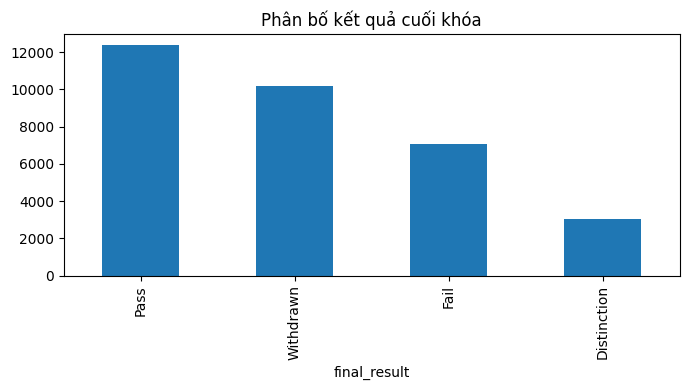

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'clht_code').exists() and (ROOT.parent / 'clht_code').exists():
    ROOT = ROOT.parent
sys.path.insert(0,str(ROOT))
DATA=ROOT/'data'
OUT=ROOT/'ket_qua'
OUT.mkdir(exist_ok=True)
import pandas as pd
import matplotlib.pyplot as plt
files=['studentInfo.csv','studentRegistration.csv','assessments.csv','studentAssessment.csv','studentVle.csv','vle.csv','courses.csv']
rows=[]
for name in files:
 d=pd.read_csv(DATA/name); rows.append({'file':name,'rows':len(d),'columns':len(d.columns),'missing':int(d.isna().sum().sum())})
summary=pd.DataFrame(rows); display(summary)
info=pd.read_csv(DATA/'studentInfo.csv'); print(info.final_result.value_counts()); print('duplicate enrollment',info.duplicated(['id_student','code_module','code_presentation']).sum())
fig,ax=plt.subplots(figsize=(7,4)); info.final_result.value_counts().plot.bar(ax=ax); ax.set_title('Phân bố kết quả cuối khóa'); fig.tight_layout(); fig.savefig(OUT/'phan_bo_nhan.png',dpi=150); plt.show()